In [1]:
import numpy as np
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense

In [2]:
# Sample dataset
X = np.array([[1], [2], [3], [4], [5]], dtype=np.float32)
y = np.array([2, 4, 6, 8, 10], dtype=np.float32)

In [3]:
X

array([[1.],
       [2.],
       [3.],
       [4.],
       [5.]], dtype=float32)

In [4]:
y

array([ 2.,  4.,  6.,  8., 10.], dtype=float32)

In [5]:
model = Sequential([
    Dense(8, activation='relu', input_shape=(1,)),
    Dense(1, activation='linear')
])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [6]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 8)              │            16 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 25 (100.00 B)

 Trainable params: 25 (100.00 B)

 Non-trainable params: 0 (0.00 B)

In [7]:
model.compile(loss='mean_squared_error', optimizer='adam')

In [14]:
history = model.fit(X, y, epochs=100, batch_size=1, validation_split=0.2)

Epoch 1/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - loss: 22.6955 - val_loss: 78.3294
Epoch 2/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - loss: 22.3417 - val_loss: 77.2233
Epoch 3/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 21.9438 - val_loss: 76.1763
Epoch 4/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - loss: 21.5956 - val_loss: 75.1270
Epoch 5/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 21.2789 - val_loss: 74.0339
Epoch 6/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - loss: 20.9073 - val_loss: 72.9748
Epoch 7/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 20.6222 - val_loss: 71.8416
Epoch 8/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - loss: 20.2254 - val_loss: 70.7793
Epoch 9/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - loss: 19.9616 - val_loss: 69.6294
Epoch 10/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - loss: 19.6233 - val_loss: 68.4884
Epoch 11/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - loss: 19.1845 - val_loss: 67.4703
Epoch 12/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step -

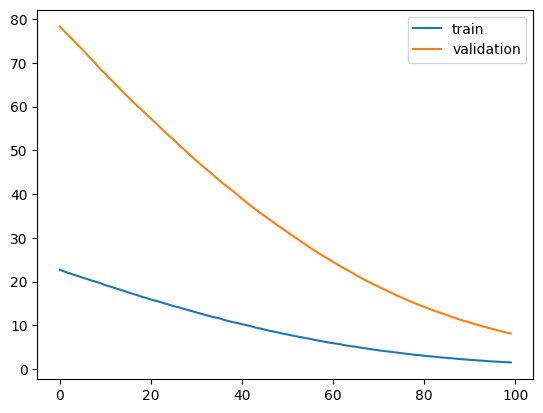

In [17]:
import matplotlib.pyplot as plt
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.legend(['train', 'validation'])
plt.show()

In [18]:
ypred = model.predict(X)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 120ms/step


In [20]:
from sklearn.metrics import r2_score
r2_score(y, ypred)

0.6466923952102661

In [21]:
import numpy as np
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense

# Input features: area, bedrooms
X = np.array([
    [1000, 2],
    [1500, 3],
    [2000, 3],
    [2500, 4],
    [3000, 5],
    [1200, 2],
    [1800, 3],
    [2800, 4]
], dtype=np.float32)

# Target: house price in lakhs
y = np.array(
    [20, 30, 38, 50, 60, 24, 36, 56],
    dtype=np.float32
)

# Scale features for easier training
X = X / np.array([1000, 5], dtype=np.float32)

In [26]:
model = Sequential([
    Dense(16, activation="relu", input_shape=(2,)),
    Dense(8, activation="relu"),
    Dense(1, activation='linear')  # One numerical prediction
])

In [29]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='mean_squared_error',
    metrics=["mse"]
)

history = model.fit(
    X, y,
    epochs=100,
    batch_size=4,
    verbose=0
)

print(
    f"Final training loss: {history.history['loss'][-1]:.4f}"
)

Final training loss: 24.1391


In [34]:
history.history

{'loss': [438.63763427734375,
  431.25830078125,
  423.3778991699219,
  415.6392822265625,
  408.34954833984375,
  400.90008544921875,
  393.90777587890625,
  386.3602294921875,
  378.329833984375,
  371.89825439453125,
  364.1250305175781,
  357.2753601074219,
  349.64404296875,
  342.72735595703125,
  336.6778564453125,
  327.816162109375,
  321.9609375,
  314.922119140625,
  308.5325927734375,
  301.1778564453125,
  295.48272705078125,
  288.3006896972656,
  282.1973876953125,
  274.87542724609375,
  269.358642578125,
  262.7438049316406,
  256.8772277832031,
  250.18609619140625,
  245.07701110839844,
  238.10853576660156,
  231.90597534179688,
  225.69924926757812,
  220.5443572998047,
  215.118896484375,
  209.6743621826172,
  203.46572875976562,
  198.57559204101562,
  193.01426696777344,
  187.79977416992188,
  182.5544891357422,
  176.99032592773438,
  172.94798278808594,
  166.96902465820312,
  161.78057861328125,
  157.3686065673828,
  153.17218017578125,
  148.9906616210937